# Part 1 — Two-Layer Neural Network with MNIST
## ECE 5831 · Fall 2026

This notebook implements **`TwoLayerNetKeras`**, trains it from scratch on
MNIST loaded through the **Keras dataset library**, and evaluates its digit
classification performance on the official test set.

Here, *two-layer network* means **two trainable Dense layers**: one hidden
layer and one output layer. The architecture is **784 → 128 → 10**. Each
28 × 28 grayscale image becomes a vector of 784 normalized pixel values;
the output contains probabilities for digits 0 through 9.

**What to look for:** the model summary, ten completed training epochs,
training/validation/test accuracy and loss, learning curves, a confusion
matrix, labeled prediction examples, and the final verification checks.

The saved outputs below come from actual execution. Re-running the notebook
trains a new model; small numerical differences across computers are normal.


## 1. Setup

Run the cells from top to bottom using **Run All** in Jupyter or VS Code.
Choose the Python kernel where TensorFlow is installed. If an import is
missing, uncomment and run the installation line below once, restart the
kernel, and run the notebook again. The first MNIST load requires internet
access; later runs use Keras' cached dataset.

The uploaded IDX files and `sample_weight.pkl` are not required here because
this assignment loads MNIST with Keras and learns new weights.


In [1]:
# Run once only if the packages are not installed, then restart the kernel.
# %pip install tensorflow numpy matplotlib pandas


In [2]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")

import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from IPython.display import display, Markdown

SEED = 42
EPOCHS = 10
BATCH_SIZE = 128
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}; Keras: {getattr(keras, '__version__', 'bundled with TensorFlow')}")
print(f"Seed: {SEED}; epochs: {EPOCHS}; batch size: {BATCH_SIZE}")
print("Available GPUs:", len(tf.config.list_physical_devices("GPU")))


Python: 3.12.14
TensorFlow: 2.20.0; Keras: 3.15.1
Seed: 42; epochs: 10; batch size: 128
Available GPUs: 0


## 2. Load and inspect MNIST

The Keras loader returns 60,000 training images and 10,000 test images.
Images have shape 28 × 28 and integer pixel values from 0 to 255. Labels
are integers from 0 through 9, which work directly with sparse categorical
cross-entropy. [Keras MNIST documentation](https://keras.io/api/datasets/mnist/)


In [3]:
(X_train_all_raw, y_train_all), (X_test_raw, y_test) = mnist.load_data()

assert X_train_all_raw.shape == (60000, 28, 28)
assert X_test_raw.shape == (10000, 28, 28)
assert y_train_all.shape == (60000,) and y_test.shape == (10000,)
assert np.array_equal(np.unique(y_train_all), np.arange(10))

print("Training images:", X_train_all_raw.shape)
print("Training labels:", y_train_all.shape)
print("Test images:    ", X_test_raw.shape)
print("Test labels:    ", y_test.shape)
print("Pixel range:    ", X_train_all_raw.min(), "to", X_train_all_raw.max())
print("Data source: tensorflow.keras.datasets.mnist.load_data()")


Training images: (60000, 28, 28)
Training labels: (60000,)
Test images:     (10000, 28, 28)
Test labels:     (10000,)
Pixel range:     0 to 255
Data source: tensorflow.keras.datasets.mnist.load_data()


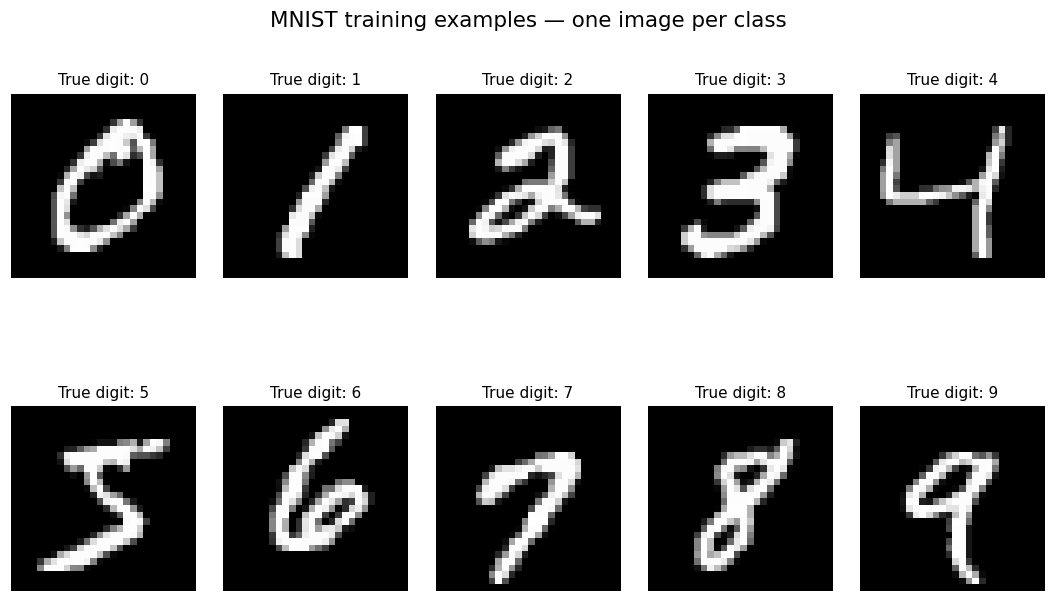

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5.8))
for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train_all == digit)[0]
    ax.imshow(X_train_all_raw[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"True digit: {digit}", fontsize=10)
    ax.axis("off")
fig.suptitle("MNIST training examples — one image per class", fontsize=14)
fig.subplots_adjust(left=0.03, right=0.97, bottom=0.04, top=0.88,
                    hspace=0.4, wspace=0.15)
plt.show()


## 3. Normalize pixels and prepare independent splits

Divide pixels by 255 to obtain values in [0, 1], then flatten each image to
784 features. A fixed random permutation divides the original training
set into **54,000 training images** and **6,000 validation images**. The
official **10,000-image test set stays separate** until final evaluation.
Validation data monitors learning; only the training split updates weights.


In [5]:
X_train_all = X_train_all_raw.reshape(-1, 784).astype("float32") / 255.0
X_test = X_test_raw.reshape(-1, 784).astype("float32") / 255.0

indices = np.random.default_rng(SEED).permutation(len(X_train_all))
val_indices = indices[:6000]
train_indices = indices[6000:]
X_train, y_train = X_train_all[train_indices], y_train_all[train_indices]
X_val, y_val = X_train_all[val_indices], y_train_all[val_indices]

assert set(train_indices).isdisjoint(set(val_indices))
assert len(train_indices) + len(val_indices) == 60000
assert X_train.dtype == np.float32
assert 0.0 <= X_train.min() <= X_train.max() <= 1.0

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Images": [len(y_train), len(y_val), len(y_test)],
    "Input features": [784, 784, 784],
    "Purpose": ["Weight updates", "Monitor learning", "Final evaluation"],
})
display(split_summary)


,Split,Images,Input features,Purpose
0,Training,54000,784,Weight updates
1,Validation,6000,784,Monitor learning
2,Test,10000,784,Final evaluation


## 4. Implement `TwoLayerNetKeras`

The hidden layer uses ReLU and the output layer uses softmax. Adam updates
the weights using sparse categorical cross-entropy. The class provides
`train`, `evaluate`, `predict_proba`, and `predict` methods around the Keras
model. TensorFlow datasets shuffle only training examples and use small
thread pools so this notebook also runs on a CPU.

The input is already flattened, so the model contains exactly **two Dense
layers**. The input layer has no trainable weights.


In [6]:
class TwoLayerNetKeras:
    """Two Dense layers for multiclass classification with Keras."""

    def __init__(self, input_size=784, hidden_size=128, output_size=10,
                 learning_rate=0.001, seed=42):
        self.seed = seed
        self.history = None
        self.model = keras.Sequential([
            keras.Input(shape=(input_size,), name="pixels"),
            keras.layers.Dense(hidden_size, activation="relu", name="hidden"),
            keras.layers.Dense(output_size, activation="softmax", name="digit"),
        ], name="TwoLayerNetKeras")
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
            loss=keras.losses.SparseCategoricalCrossentropy(),
            metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        )

    def _dataset(self, X, y=None, batch_size=128, shuffle=False):
        data = X if y is None else (X, y)
        dataset = tf.data.Dataset.from_tensor_slices(data)
        if shuffle:
            dataset = dataset.shuffle(len(X), seed=self.seed,
                                      reshuffle_each_iteration=True)
        dataset = dataset.batch(batch_size)
        options = tf.data.Options()
        options.threading.private_threadpool_size = 2
        options.threading.max_intra_op_parallelism = 1
        return dataset.with_options(options).prefetch(1)

    def train(self, X, y, validation_data=None, epochs=10,
              batch_size=128, verbose=2):
        train_data = self._dataset(X, y, batch_size, shuffle=True)
        val_data = None
        if validation_data is not None:
            X_valid, y_valid = validation_data
            val_data = self._dataset(X_valid, y_valid, batch_size)
        self.history = self.model.fit(
            train_data, validation_data=val_data,
            epochs=epochs, verbose=verbose, shuffle=False,
        )
        return self.history

    def evaluate(self, X, y, batch_size=128):
        return self.model.evaluate(
            self._dataset(X, y, batch_size),
            verbose=0, return_dict=True,
        )

    def predict_proba(self, X, batch_size=128):
        return self.model.predict(self._dataset(X, batch_size=batch_size),
                                  verbose=0)

    def predict(self, X, batch_size=128):
        return self.predict_proba(X, batch_size).argmax(axis=1)


network = TwoLayerNetKeras(seed=SEED)
network.model.summary()
assert sum(isinstance(layer, keras.layers.Dense)
           for layer in network.model.layers) == 2


Model: "TwoLayerNetKeras"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digit (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 101,770 (397.54 KB)
 Trainable params: 101,770 (397.54 KB)
 Non-trainable params: 0 (0.00 B)


## 5. Train the model

The untrained validation score provides a baseline. Training then runs for
ten complete epochs and prints training and validation loss and accuracy
after each epoch. The model begins with newly initialized weights.


In [7]:
untrained_val = network.evaluate(X_val, y_val)
initial_weights = [w.copy() for w in network.model.get_weights()]
print(f"Before training — validation loss: {untrained_val['loss']:.4f}, "
      f"accuracy: {untrained_val['accuracy']:.2%}")

start_time = time.perf_counter()
history = network.train(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
)
training_seconds = time.perf_counter() - start_time
print(f"\nTraining completed: {len(history.epoch)} epochs "
      f"in {training_seconds:.1f} seconds.")


Before training — validation loss: 2.3934, accuracy: 10.48%
Epoch 1/10
422/422 - 1s - 3ms/step - accuracy: 0.8997 - loss: 0.3710 - val_accuracy: 0.9385 - val_loss: 0.2158
Epoch 2/10
422/422 - 1s - 2ms/step - accuracy: 0.9523 - loss: 0.1688 - val_accuracy: 0.9572 - val_loss: 0.1537
Epoch 3/10
422/422 - 1s - 2ms/step - accuracy: 0.9639 - loss: 0.1220 - val_accuracy: 0.9662 - val_loss: 0.1261
Epoch 4/10
422/422 - 1s - 2ms/step - accuracy: 0.9732 - loss: 0.0937 - val_accuracy: 0.9665 - val_loss: 0.1120
Epoch 5/10
422/422 - 1s - 2ms/step - accuracy: 0.9780 - loss: 0.0762 - val_accuracy: 0.9695 - val_loss: 0.1029
Epoch 6/10
422/422 - 1s - 2ms/step - accuracy: 0.9815 - loss: 0.0635 - val_accuracy: 0.9718 - val_loss: 0.0939
Epoch 7/10
422/422 - 1s - 2ms/step - accuracy: 0.9847 - loss: 0.0527 - val_accuracy: 0.9707 - val_loss: 0.0923
Epoch 8/10
422/422 - 1s - 2ms/step - accuracy: 0.9874 - loss: 0.0437 - val_accuracy: 0.9753 - val_loss: 0.0873
Epoch 9/10
422/422 - 1s - 2ms/step - accuracy: 0.989

,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.8997,0.3710,0.9385,0.2158
1,2,0.9523,0.1688,0.9572,0.1537
2,3,0.9639,0.1220,0.9662,0.1261
3,4,0.9732,0.0937,0.9665,0.1120
4,5,0.9780,0.0762,0.9695,0.1029
5,6,0.9815,0.0635,0.9718,0.0939
6,7,0.9847,0.0527,0.9707,0.0923
7,8,0.9874,0.0437,0.9753,0.0873
8,9,0.9898,0.0369,0.9753,0.0840
9,10,0.9915,0.0317,0.9768,0.0820


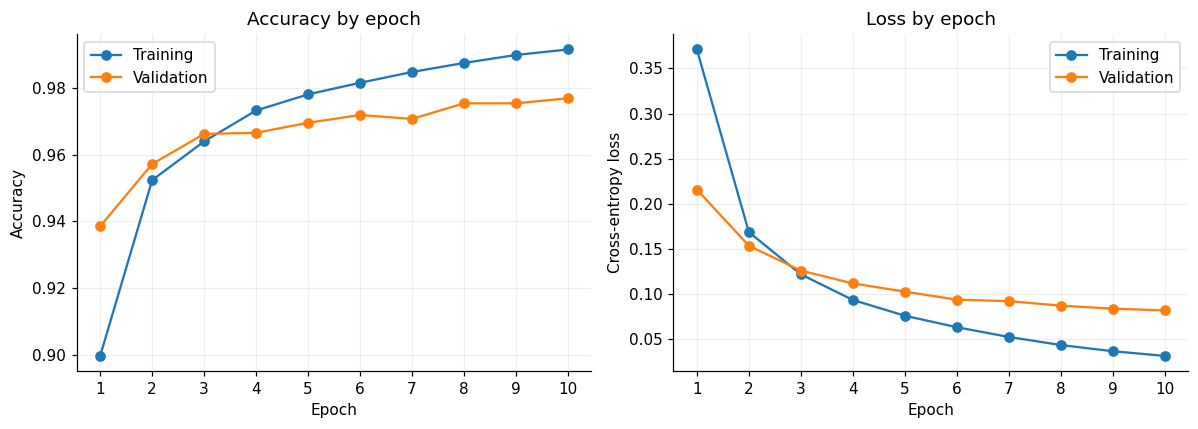

In [8]:
history_table = pd.DataFrame(history.history)
history_table.insert(0, "epoch", np.arange(1, len(history_table) + 1))
display(history_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs_completed = history_table["epoch"]
axes[0].plot(epochs_completed, history.history["accuracy"], "o-", label="Training")
axes[0].plot(epochs_completed, history.history["val_accuracy"], "o-", label="Validation")
axes[0].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy")
axes[1].plot(epochs_completed, history.history["loss"], "o-", label="Training")
axes[1].plot(epochs_completed, history.history["val_loss"], "o-", label="Validation")
axes[1].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
for ax in axes:
    ax.set_xticks(epochs_completed)
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


## 6. Evaluate training, validation, and test performance

These scores are computed with the **final trained weights** using
`model.evaluate`. The training score can differ from the last epoch's
logged accuracy because that log averages batches while weights are still
changing. The test score estimates performance on unseen MNIST examples.


In [9]:
train_results = network.evaluate(X_train, y_train)
val_results = network.evaluate(X_val, y_val)
test_results = network.evaluate(X_test, y_test)

evaluation = pd.DataFrame([
    {"Split": name, "Images": count, "Loss": result["loss"],
     "Accuracy (%)": 100 * result["accuracy"]}
    for name, count, result in [
        ("Training", len(y_train), train_results),
        ("Validation", len(y_val), val_results),
        ("Test", len(y_test), test_results),
    ]
])
display(evaluation.round({"Loss": 4, "Accuracy (%)": 2}))
print(f"Test accuracy: {test_results['accuracy']:.2%}")
print(f"Test loss: {test_results['loss']:.4f}")


Test accuracy: 97.72%
Test loss: 0.0738


,Split,Images,Loss,Accuracy (%)
0,Training,54000,0.0233,99.50
1,Validation,6000,0.0820,97.68
2,Test,10000,0.0738,97.72


## 7. Inspect predictions and errors

The largest softmax probability determines the predicted digit. The
confusion matrix counts true labels by row and predicted labels by column.
Correct predictions lie on the diagonal. The displayed probability is a
model score, not a guarantee that a prediction is correct.


Correct test predictions: 9,772 / 10,000
Incorrect test predictions: 228


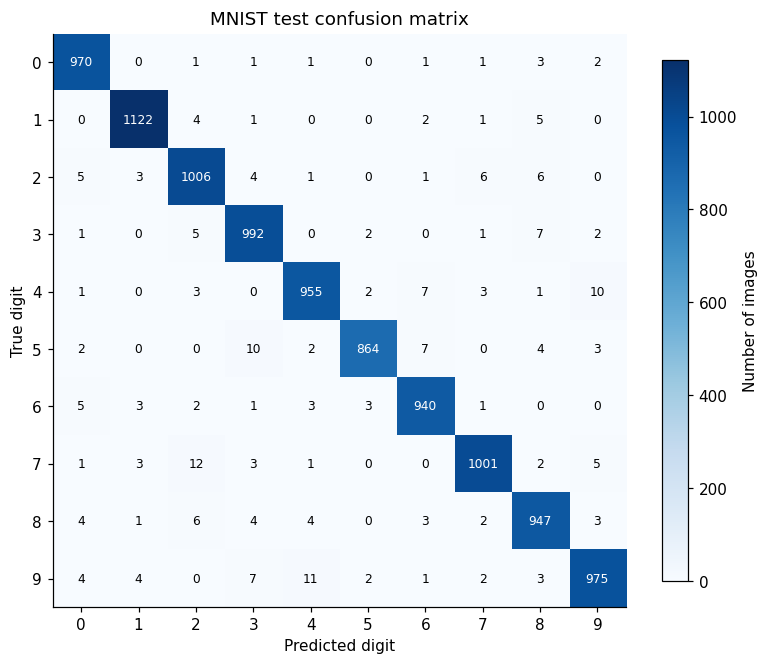

In [10]:
test_probabilities = network.predict_proba(X_test)
y_pred = test_probabilities.argmax(axis=1)
correct_count = int(np.count_nonzero(y_pred == y_test))
print(f"Correct test predictions: {correct_count:,} / {len(y_test):,}")
print(f"Incorrect test predictions: {len(y_test) - correct_count:,}")

confusion = tf.math.confusion_matrix(y_test, y_pred, num_classes=10).numpy()
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(confusion, cmap="Blues")
fig.colorbar(im, ax=ax, label="Number of images", shrink=0.85)
ax.set(xticks=range(10), yticks=range(10), xlabel="Predicted digit",
       ylabel="True digit", title="MNIST test confusion matrix")
for true in range(10):
    for predicted in range(10):
        count = confusion[true, predicted]
        ax.text(predicted, true, str(count), ha="center", va="center",
                color="white" if count > confusion.max() / 2 else "black",
                fontsize=8)
plt.tight_layout()
plt.show()


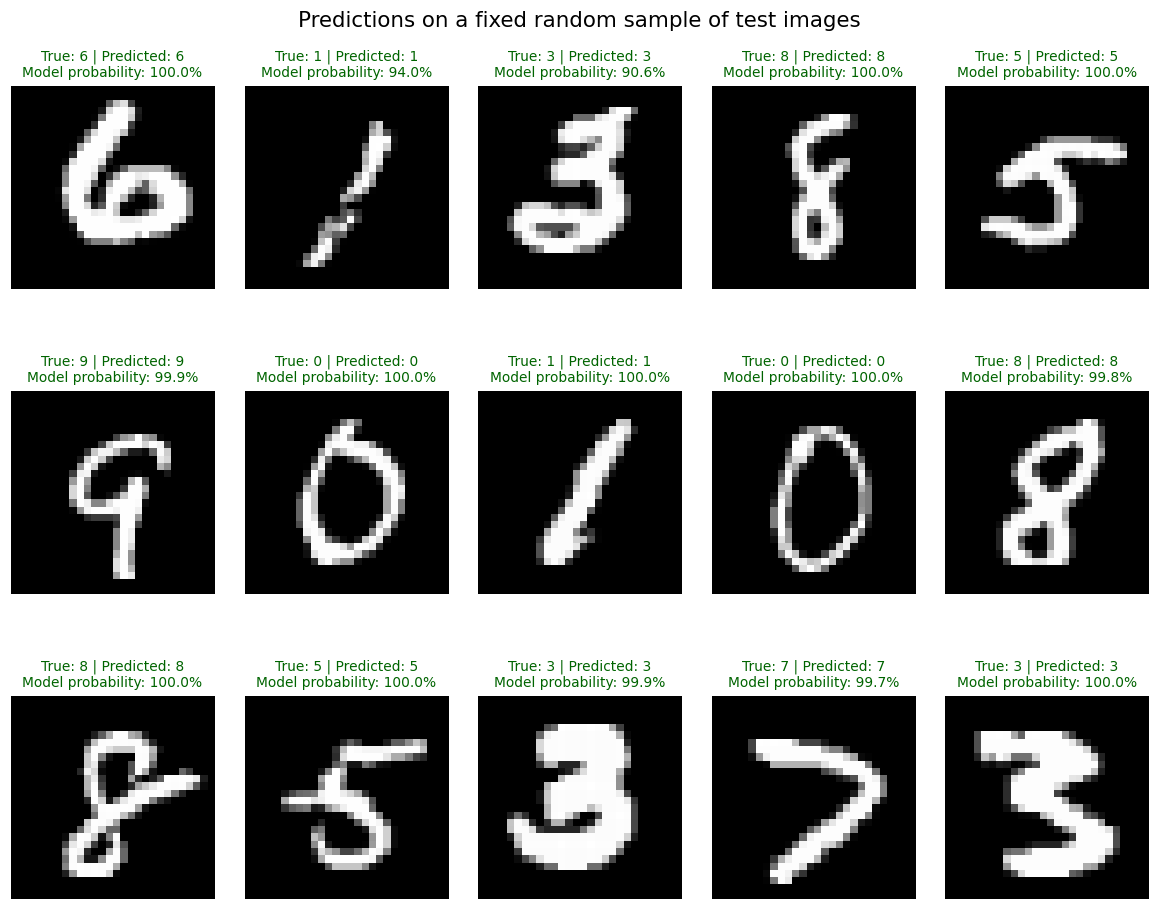

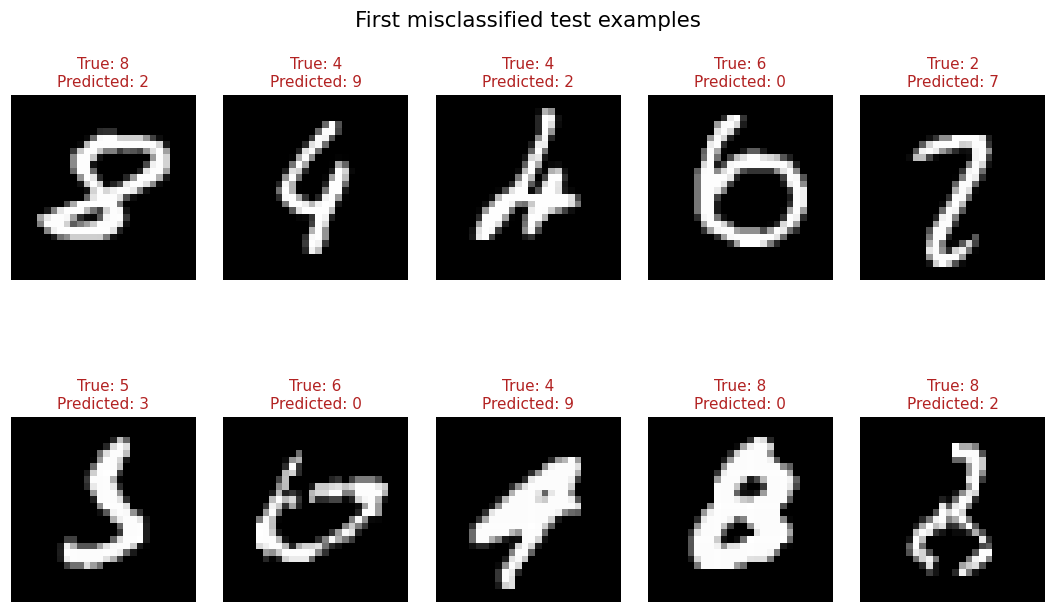

In [11]:
example_indices = np.random.default_rng(SEED + 1).choice(len(y_test), 15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(11, 8.5))
for ax, index in zip(axes.flat, example_indices):
    predicted = int(y_pred[index])
    true = int(y_test[index])
    ax.imshow(X_test_raw[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"True: {true} | Predicted: {predicted}\n"
                 f"Model probability: {test_probabilities[index, predicted]:.1%}",
                 color="darkgreen" if true == predicted else "firebrick", fontsize=9)
    ax.axis("off")
fig.suptitle("Predictions on a fixed random sample of test images", fontsize=14)
fig.subplots_adjust(left=0.03, right=0.97, bottom=0.03, top=0.90,
                    hspace=0.5, wspace=0.15)
plt.show()

wrong_indices = np.flatnonzero(y_pred != y_test)[:10]
if len(wrong_indices):
    fig, axes = plt.subplots(2, 5, figsize=(10, 5.8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, wrong_indices):
        ax.imshow(X_test_raw[index], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"True: {int(y_test[index])}\nPredicted: {int(y_pred[index])}",
                     color="firebrick", fontsize=10)
    fig.suptitle("First misclassified test examples", fontsize=14)
    fig.subplots_adjust(left=0.03, right=0.97, bottom=0.04, top=0.86,
                        hspace=0.6, wspace=0.15)
    plt.show()
else:
    print("No test images were misclassified in this run.")


## 8. Verify the run and summarize the measured results

The following checks confirm that training completed, weights changed,
all recorded values are finite, predictions have the correct shape and
probability sums, and independently counted accuracy agrees with Keras.
They verify the workflow without assuming a particular accuracy score.


In [12]:
assert len(history.epoch) == EPOCHS
assert np.isfinite(history_table.to_numpy()).all()
assert any(not np.array_equal(before, after)
           for before, after in zip(initial_weights, network.model.get_weights()))
assert test_probabilities.shape == (10000, 10)
assert np.isfinite(test_probabilities).all()
assert np.allclose(test_probabilities.sum(axis=1), 1.0, atol=1e-5)
assert np.isclose((y_pred == y_test).mean(), test_results["accuracy"], atol=1e-6)
assert confusion.sum() == len(y_test)
assert np.isfinite(evaluation[["Loss", "Accuracy (%)"]].to_numpy()).all()
print("PASS: training, evaluation, and prediction checks completed successfully.")

loss_change = history.history["loss"][0] - history.history["loss"][-1]
generalization_gap = 100 * (train_results["accuracy"] - test_results["accuracy"])
display(Markdown(
    f"### Results from this execution\n\n"
    f"The network completed **{EPOCHS} epochs** using **{len(y_train):,} training images**. "
    f"Its final training accuracy was **{train_results['accuracy']:.2%}**, "
    f"validation accuracy was **{val_results['accuracy']:.2%}**, and "
    f"test accuracy was **{test_results['accuracy']:.2%}**. "
    f"It correctly classified **{correct_count:,} of {len(y_test):,}** test images.\n\n"
    f"The untrained validation accuracy was {untrained_val['accuracy']:.2%}. "
    f"The first-to-last-epoch training loss reduction was {loss_change:.4f}. "
    f"Training accuracy minus test accuracy was {generalization_gap:.2f} percentage points. "
    "The learning curves and misclassified examples provide additional evidence "
    "about learning and the remaining errors. This evaluation applies to MNIST "
    "and does not establish performance on arbitrary photographs of handwritten digits."
))


PASS: training, evaluation, and prediction checks completed successfully.


### Results from this execution

The network completed **10 epochs** using **54,000 training images**. Its final training accuracy was **99.50%**, validation accuracy was **97.68%**, and test accuracy was **97.72%**. It correctly classified **9,772 of 10,000** test images.

The untrained validation accuracy was 10.48%. The first-to-last-epoch training loss reduction was 0.3393. Training accuracy minus test accuracy was 1.78 percentage points. The learning curves and misclassified examples provide additional evidence about learning and the remaining errors. This evaluation applies to MNIST and does not establish performance on arbitrary photographs of handwritten digits.

## References

- [Keras: MNIST digits classification dataset](https://keras.io/api/datasets/mnist/)
- [TensorFlow: Training and evaluation with built-in methods](https://www.tensorflow.org/guide/keras/training_with_built_in_methods)

The code above uses the documented Keras dataset, model training,
evaluation, and prediction APIs. All numerical results in this notebook
are produced by its executed cells.
